# Model Comparison
Showing results from K-fold cross validation and PSIS-LOO

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scienceplots

assert scienceplots
plt.style.use(["science", "notebook"])

from utils import pretty_model_names

In [2]:
def paired_comparison(pointwise):
    """Mean per-stratum deviance difference from the best model, with paired SE"""
    mean = {name: values.mean() for name, values in pointwise.items()}
    best = min(mean, key=mean.get)
    rows = []
    for name, values in pointwise.items():
        diff = (values - pointwise[best]).dropna()
        rows.append(
            {
                "model": name,
                "diff": diff.mean(),
                "diff_se": diff.std(ddof=1) / np.sqrt(len(diff)),
            }
        )
    return pd.DataFrame(rows)


def plot_comparison(df, xlabel, title):
    """Mean deviance per stratum with SE"""
    df = df.sort_values("deviance", ascending=False).reset_index(drop=True)
    plt.errorbar(
        y=df["model"].replace(pretty_model_names),
        x=df["deviance"],
        xerr=df["se"],
        linestyle="",
        color="black",
        marker="o",
        mfc="white",
    )
    plt.axvline(x=df.iloc[-1]["deviance"], color="gray", linestyle="--")
    plt.xlabel(xlabel)
    plt.title(title)
    plt.show()
    return df

## Model Comparison

### K-Fold Cross Validation

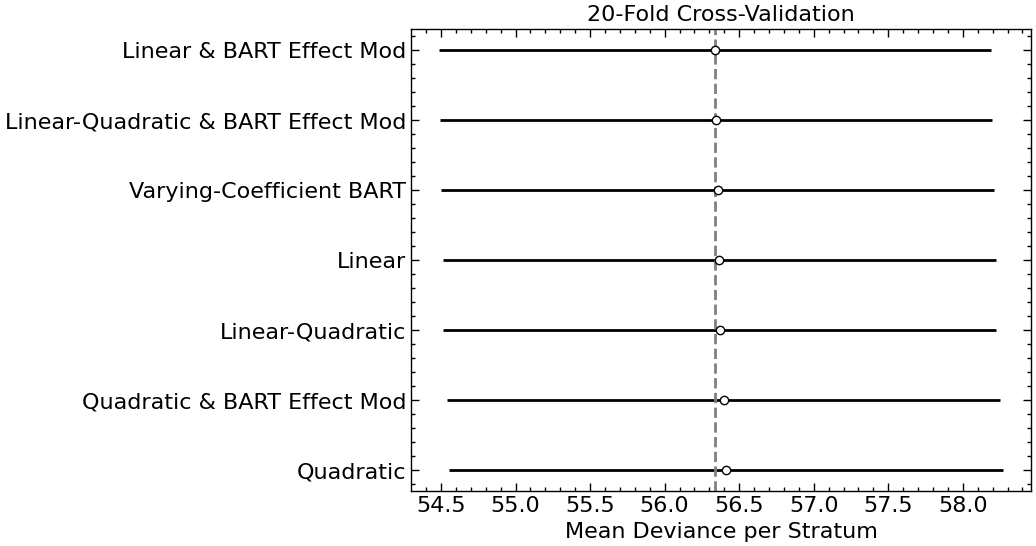

,model,deviance,se,n_strata,n_splits,diff,diff_se
0,quadratic,56.412271,1.857698,537,20,0.071233,0.028555
1,quadratic_bart,56.397084,1.854052,537,20,0.056046,0.023654
2,linear_quadratic,56.370454,1.855102,537,20,0.029416,0.017545
3,linear,56.368175,1.855007,537,20,0.027136,0.017119
4,varying_coefficient_bart,56.355829,1.852949,537,20,0.014791,0.012707
5,linear_quadratic_bart,56.344588,1.851596,537,20,0.003549,0.003340
6,linear_bart,56.341038,1.851357,537,20,0.000000,0.000000


In [3]:
folder = Path("../results/cross_validation")
rows = []
pointwise = {}
for p in sorted(folder.glob("*_cv_results.json")):
    if "_fold_" in p.name:
        continue
    j = json.loads(p.read_text())
    summary = j["summary"]
    rows.append(
        {
            "model": j["model"],
            "deviance": summary["deviance"],
            "se": summary["deviance_se"],
            "n_strata": summary["n_strata"],
            "n_splits": j["n_splits"],
        }
    )
    folds = j["fold_results"]
    pointwise[j["model"]] = pd.Series(
        -2 * np.concatenate([f["stratum_lpd"] for f in folds]),
        index=np.concatenate([f["stratum_ids"] for f in folds]),
    )

cv = pd.DataFrame(rows).merge(paired_comparison(pointwise), on="model")
n_splits = cv["n_splits"].iloc[0]
cv = plot_comparison(
    cv, "Mean Deviance per Stratum", f"{n_splits}-Fold Cross-Validation"
)
cv

### PSIS-LOO


In [4]:
# Read psis loo results
loo_folder = Path("../results/psis_loo")
rows = []
loo_pointwise = {}
for p in sorted(loo_folder.glob("*_loo.json")):
    j = json.loads(p.read_text())
    n = j["n_data_points"]  # strata with deaths
    rows.append(
        {
            "model": j["model"],
            "deviance": j["loo"] / n,
            "se": j["loo_se"] / n,
            "max_pareto_k": j["max_pareto_k"],
            "n_pareto_k_above_0.7": j["n_pareto_k_above_0.7"],
        }
    )
    loo_pointwise[j["model"]] = pd.Series(j["loo_i"], index=j["stratum_ids"])
    print(f"Loaded {j['model']}: {p.name}")

compare = pd.DataFrame(rows).merge(paired_comparison(loo_pointwise), on="model")
compare

Loaded linear_bart: linear_bart_loo.json
Loaded linear: linear_loo.json
Loaded linear_quadratic_bart: linear_quadratic_bart_loo.json
Loaded linear_quadratic: linear_quadratic_loo.json
Loaded quadratic_bart: quadratic_bart_loo.json
Loaded quadratic: quadratic_loo.json
Loaded varying_coefficient_bart: varying_coefficient_bart_loo.json


,model,deviance,se,max_pareto_k,n_pareto_k_above_0.7,diff,diff_se
0,linear_bart,56.274305,1.847789,0.340380,0,0.000000,0.000000
1,linear,56.368287,1.853195,0.146037,0,0.093981,0.018705
2,linear_quadratic_bart,56.280162,1.847990,0.312878,0,0.005857,0.003049
3,linear_quadratic,56.370492,1.853273,0.192555,0,0.096187,0.018821
4,quadratic_bart,56.322238,1.850421,0.274061,0,0.047933,0.024923
5,quadratic,56.413367,1.855941,0.141266,0,0.139062,0.029664
6,varying_coefficient_bart,56.280075,1.848184,0.141844,0,0.005769,0.013268


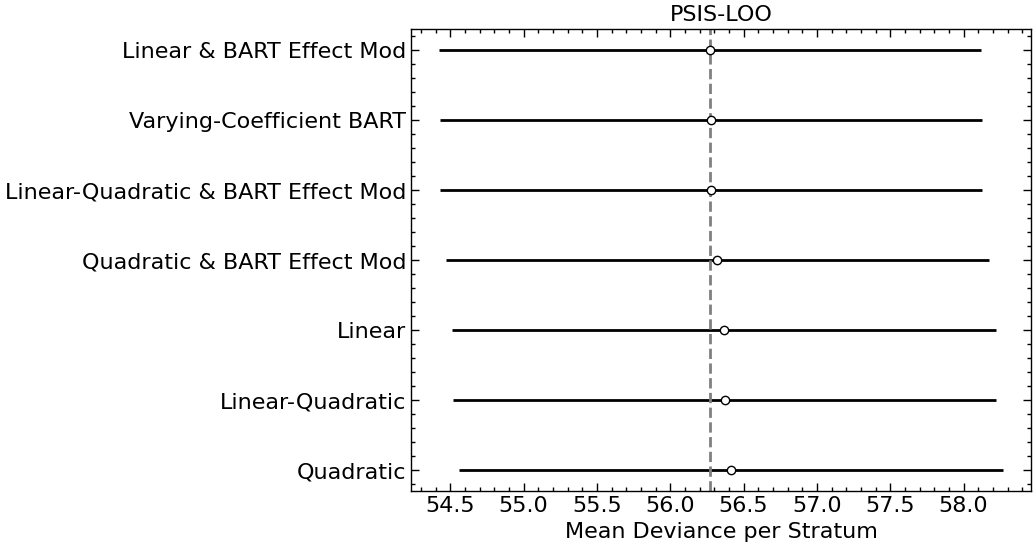

,model,deviance,se,max_pareto_k,n_pareto_k_above_0.7,diff,diff_se
0,quadratic,56.413367,1.855941,0.141266,0,0.139062,0.029664
1,linear_quadratic,56.370492,1.853273,0.192555,0,0.096187,0.018821
2,linear,56.368287,1.853195,0.146037,0,0.093981,0.018705
3,quadratic_bart,56.322238,1.850421,0.274061,0,0.047933,0.024923
4,linear_quadratic_bart,56.280162,1.847990,0.312878,0,0.005857,0.003049
5,varying_coefficient_bart,56.280075,1.848184,0.141844,0,0.005769,0.013268
6,linear_bart,56.274305,1.847789,0.340380,0,0.000000,0.000000


In [6]:
compare = plot_comparison(compare, "Mean Deviance per Stratum", "PSIS-LOO")
compare